<a href="https://colab.research.google.com/github/nagakokobot/pytorch/blob/master/Numpy/Averaged_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Averaged perceptron

- It is a modification of the standard perceptron. It improves the stability and generalization by computing the average of all the weight vectors generated during training.
- In this script I will train an averaged perceptron and compare its accuracy with a standard perceptron
- I will use iris dataset. I will explore the dataset first using pandas and numpy.


In [46]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mp
import pandas as pd

In [47]:
dataset_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data'
dataset = pd.read_csv(dataset_url, header = None)
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       150 non-null    float64
 1   1       150 non-null    float64
 2   2       150 non-null    float64
 3   3       150 non-null    float64
 4   4       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [48]:
dataset.head()

,0,1,2,3,4
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [49]:
dataset.iloc[:,4].unique()

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

In [50]:
dataset[4].value_counts()

,count
4,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


- **About the Dataset**
- It has 5 columns with 150 instances
- |float|float|flaot|float|categorical|.
- The first four columns are the features and the last row is the target column(flower species)
- Each species has 50 instances and 3 classes `array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)`.
- since we want to work wih perceptron (a binary classifier). We will only use the first two classes.

## Data Prep
- first convert the target variables into int.
- Use only the first 100 instances (two classes) and first two features
- We use 1 for the class Iris-setosa and -1 for Iris-versicolor

In [51]:
dataset[4] = np.where(dataset.iloc[:,4] == 'Iris-setosa', 1, -1)

In [52]:
dataset.iloc[[1,2, 99,100],:]

,0,1,2,3,4
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
99,5.7,2.8,4.1,1.3,-1
100,6.3,3.3,6.0,2.5,-1


In [53]:
# Let us divide the training set into features and labels.
# But let us convert the dataset into numpy array
np_data = np.asarray(dataset, dtype = 'float64')

x_train = np_data[:100,:2]

y_train = np_data[:100,-1]

## Implement the perceptron

- weight update for averaged perceptron:
  - $w_{avg} ← w_{avg} + c⋅w_t $ - average calculation
  - $w_{t+1} = w_{t} + y_i \cdot x_i$ - weight update
- Similarly for bias
  - $b_{\text{ave}} \leftarrow b_{\text{ave}} + c \cdot b_{(t)}$
  - $b_{(t+1)} = b_{(t)} + y_i$

In [71]:
print(x_train.shape)
nSamples, dim = x_train.shape

(100, 2)


In [70]:
#Initilization
nSamples, dim = x_train.shape
max_iter = 10

# Initilize weights for both standard and avraged perceptron
w = np.zeros([1,dim])   # (1,2)
b = np.zeros([1,1])     # (1,1)

w_avg = np.zeros([1,dim])   # (1,2)
b_avg = np.zeros([1,1])     # (1,1)

# initilize placeholders for logging accuracy to plot after training
acc = []
acc_avg = []

#set up random seed for reproducable results
np.random.seed(10)

#start the iterations to train our perceptron.
for cur_iter in range(max_iter):
  print(cur_iter)
  c = 1  #counter to calculate the number of correct predictions
  # shuffel the index of the dataset at the start of each epoch
  rand_idx = np.random.permutation(nSamples)
  # loop through each random index, extract the datapoint from x_train, predict
  # and update the weights only wwhen the prediction is incorrect
  for idx in rand_idx:
    x_i = x_train[idx]  #(2,)
    y_i = y_train[idx]

    #calculate prediction
    y_hat = np.sign(np.dot(w, x_i) + b)

    #only update the weights when the prediction is wrong
    if (not y_hat == y_i):
      # update weights and reset c
      print(f"updating weights in iter {cur_iter}")
      # for avg perceptron
      w_avg += c*w
      b_avg += c*b

      w += y_i*x_i
      b += y_i

      # reset counter
      c =1
    else: # if prediction is correct
      c += 1
  # calculate the output for each sample in each iteration using the averaged weights and bias
  y_hat_avg = np.sign(np.matmul(x_train , w_avg.T) + b_avg)
  # Calculate the accuracy for each epoch
  # acc = (no.of correct pred) / (total number of samples)
  acc_avg_i = (y_hat_avg.squeeze() == y_train.squeeze()).mean()
  acc_avg.append(acc_avg_i)

  # Calculate the output using standard weights
  y_hat_std = np.sign(np.matmul(x_train, w.T) + b)
  acc_std_i = (y_hat_std.squeeze() == y_train.squeeze()).mean()
  acc.append(acc_std_i)

  print(f"iteration {cur_iter+1}: with accuracy: {acc_std_i} and avg_acc: {acc_avg_i}")



0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
updating weights in iter 0
iteration 1: with accuracy: 0.5 and avg_acc: 0.94
1
updating weights in iter 1
u

Text(0.5, 1.0, 'Average vs Vanilla Perceptron')

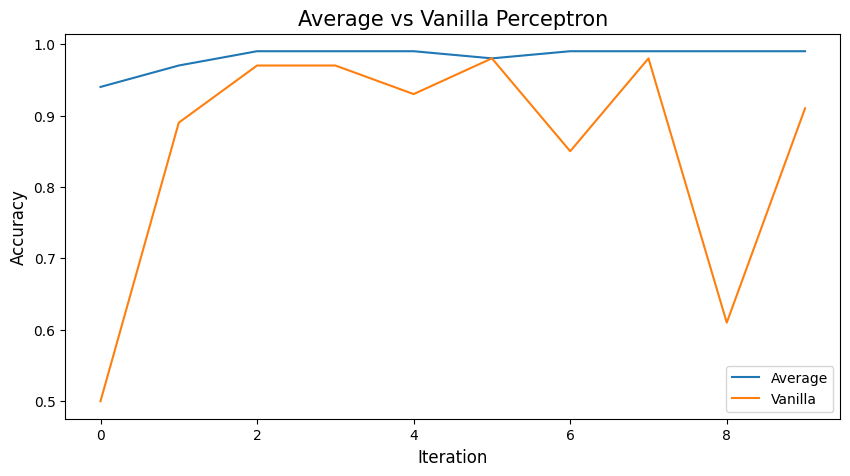

In [63]:
plt.figure(figsize = (10, 5))
plt.plot(acc_avg)
plt.plot(acc)
plt.legend(["Average", "Vanilla"])

plt.xlabel('Iteration', size=12)
plt.ylabel('Accuracy', size=12)
plt.title("Average vs Vanilla Perceptron", size=15)

summary:
- As expected the averaged perceptron is much more stable than the standard perceptron.
- Meaning, the averaged perceptron is not as sensitive to outliers as standard perceptron.